<a href="https://colab.research.google.com/github/rlacey2468/Machine_Learning_Class_Projects/blob/main/Copy_of_CS_536_Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS 536 Assignment 1: Linear Regression on Ford Ranger Prices

**Rachel Lacey**

Given Functions:


Error:

$$
e^{(i)} = h_\theta(x^{(i)}) - y^{(i)}
$$

Cost function:

$$
J(\theta)=
\frac{1}{m}\sum_{i=1}^{m}
\left[
(e^{(i)})^2 + 0.1(e^{(i)})^4
\right]
$$


## Gradient

The gradient for $\theta_0$ is:

$$
\frac{\partial J}{\partial \theta_0}
=
\frac{1}{m}
\sum_{i=1}^{m}
\left[
2e^{(i)} + 0.4(e^{(i)})^3
\right]
$$

The gradient for $\theta_1$ is:

$$
\frac{\partial J}{\partial \theta_1}
=
\frac{1}{m}
\sum_{i=1}^{m}
\left[
2e^{(i)} + 0.4(e^{(i)})^3
\right]x^{(i)}
$$

## Regular Model Results


### Final Values of Theta

- Min price:
  $\theta_0 \approx 0.00495$
  and $\theta_1 \approx 10.029$

- Max price:
  $\theta_0 \approx 0.00880$
  and $\theta_1 \approx 17.879$

The final losses were approximately $5.39\times10^{14}$ for the minimum
price model and $3.78\times10^{15}$ for the maximum price model.

### Predicted Missing Years

| Year | Predicted Min | Predicted Max |
|---|---:|---:|
| 2012 | $20,178 | $35,973 |
| 2013 | $20,188 | $35,991 |
| 2014 | $20,198 | $36,009 |
| 2015 | $20,208 | $36,026 |
| 2016 | $20,218 | $36,044 |
| 2017 | $20,228 | $36,062 |
| 2018 | $20,238 | $36,080 |

## Scaled + Dynamic Learning Rate Results

### Final Values of Theta

- Min price:
  $\theta_0 \approx 17,233.59$
  and $\theta_1 \approx 7,595.09$

- Max price:
  $\theta_0 \approx 31,836.17$
  and $\theta_1 \approx 11,991.35$

The final losses were approximately $1.29\times10^{13}$ for the minimum
price model and $6.65\times10^{13}$ for the maximum price model.

### Predicted Missing Years

| Year | Predicted Min | Predicted Max |
|---|---:|---:|
| 2012 | $18,010 | $33,062 |
| 2013 | $18,823 | $34,346 |
| 2014 | $19,636 | $35,630 |
| 2015 | $20,450 | $36,914 |
| 2016 | $21,263 | $38,198 |
| 2017 | $22,076 | $39,481 |
| 2018 | $22,889 | $40,765 |

## Comparison

The scaled + dynamic learning rate model showed a lot of
improvement compared to the regular model. The regular model produced basically
flat predictions for the missing years.

After adding scaling and a dynamic learning rate,
the predictions increased pretty steadily from 2012 through 2018. The final
losses were also lower than those of the regular model.


## Summary

The regular model,  produced final theta values of $\theta_0 \approx 0.00495$ and $\theta_1 \approx 10.029$ for the minimum-price model, and $\theta_0 \approx 0.00880$ and $\theta_1 \approx 17.879$ for the maximum-price model. Its final losses were approximately $5.39\times10^{14}$ for minimum price and $3.78\times10^{15}$ for maximum price. I was not able to get the regular model to converge sufficiently within the 100 iterations, resulting in flat predictions for the missing 2012--2018 years.

The scaled + dynamic learning rate model performed much better. Its final theta values were $\theta_0 \approx 17,233.59$ and $\theta_1 \approx 7,595.09$ for minimum price, and $\theta_0 \approx 31,836.17$ and $\theta_1 \approx 11,991.35$ for maximum price. Its final losses were approximately $1.29\times10^{13}$ and $6.65\times10^{13}$, respectively. Using this model, the predicted 2026 price range is approximately $29,400 to $51,000. Overall, the scaled model produced lower losses and a more realistic upward trend than the regular model. I would really want to improve on the regular model  by increasing the number of iterations so it can reach convergence, further tuning the learning rate: I want to try using 8x10^16 or 3x10^16 to see if the learning rate can be optimized, using additional training data like 1993-1997. Based on the predicted 2026 price range (29,400-57,270), I would consider buying a next-generation Ranger at the minimum or mid price, since I've seen newer cars with worse performace be sold at a price higher than the Ford Ranger.


# **Linear Regression Model**

In [ ]:
!pip install numpy matplotlib

**Initialization**

Imports


In [ ]:
# Math library and library for plots
import numpy as np
import matplotlib.pyplot as plt

Ford Ranger Data


In [ ]:
# Data will be collected by hand from website
# Chosen years: 1998-2011 then 2019- 2026
years = np.array([
    1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005,
    2006, 2007, 2008, 2009, 2010, 2011,
    2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026
])
# Minimun Price:
min_prices = np.array([
    11485, 11845, 11580, 11960, 12565, 13645, 14575, 14610,
    14450, 13970, 14490, 16395, 17820, 18160,
    24000, 24110, 24820, 25980, 27400, 32820, 33350, 33550
])
# Maximum Price:
max_prices = np.array([
    19695, 19435, 19785, 24335, 25010, 25450, 26015, 26795,
    26670, 24425, 24350, 25805, 25800, 26070,
    38565, 38675, 39035, 39730, 40945, 55720, 56070, 57270
])

# Missing Years: 2012-2018
missing_years = np.arange(2012, 2019)

Cost Function

In [ ]:
# Cost function: calculating loss using the function provided
# parameters: X, Y, Theta 0, Theta 1
# returns: cost
def cost_function(x, y, theta_0, theta_1):
    #getting length of y
    m = len(y)

    # Make predictions
    predictions = theta_0 + theta_1 * x

    # Calculate errors
    errors = predictions - y

    # Calculate cost
    cost = np.sum(errors**2 + 0.1 * errors**4) / m

    return cost

Gradient Descent Function

In [ ]:
# Gradient Descent Function
# parameters: X, Y, Theta 0, Theta 1 Learning rate
# returns: updated theta, cost over time (for plots)
# returning mean and standard deviation for predictions
# added booleans for scaled and dynamic, used functions on slides
def gradient_descent(x, y, theta_0, theta_1, learning_rate,
 scaled=False, dynamic=False):

    #Setting iterations to 100
    iterations = 100

    # Store cost for every iteration
    cost_history = []

    #length of y
    m = len(y)

    #mean and standard deviation
    x_mean = None
    x_std = None

    # Feature scaling
    if scaled:
        x_mean = np.mean(x)
        x_std = np.std(x)
        x = (x - x_mean) / x_std

    for i in range(iterations):

        # Dynamic learning rate
        if dynamic:
            current_learning_rate = learning_rate / (1 + 0.01 * i)
        else:
            current_learning_rate = learning_rate

        # Predictions
        predictions = theta_0 + theta_1 * x

        # Errors
        errors = predictions - y

        # Calculate gradient
        gradient_term = 2 * errors + 0.4 * errors**3

        gradient_theta0 = np.sum(gradient_term) / m

        gradient_theta1 = np.sum(
            gradient_term * x
        ) / m

        # Update weights
        theta_0 = theta_0 - current_learning_rate * gradient_theta0
        theta_1 = theta_1 - current_learning_rate * gradient_theta1

        # Calculate cost
        cost = cost_function(
            x, y, theta_0, theta_1
        )

        cost_history.append(cost)

    return theta_0, theta_1, cost_history, x_mean, x_std

Prediction Function


In [ ]:
# Used to calculate and return predicted prices
# Parameters: X, Theta 0, Theta 1
# Returns: predicted prices
def prediction_function(x, theta_0, theta_1):

    # Calculate predicted values using the trained model
    predictions = theta_0 + theta_1 * x

    return predictions

Bias, Weight, Learning rate

In [ ]:
#Initial Bias (theta_0)
bias = 20000

#Initial Weight (theta_1)
weight = 1

#Learning rate (learning_rate)
learning_rate = 8.2e-16

#learning rate for scaled + dynamic
learning_rate_sd = 2e-9


**Training**

Running Gradient Descent Function

In [ ]:
# Min price: regular
theta_0_min, theta_1_min, loss_min, _, _ = gradient_descent(
    years, min_prices, 0, 0, learning_rate,
    scaled=False, dynamic=False
)

# Max price: regular
theta_0_max, theta_1_max, loss_max, _, _ = gradient_descent(
    years, max_prices, 0, 0, learning_rate,
    scaled=False, dynamic=False
)

# Min price: scaled + dynamic
theta_0_min_sd, theta_1_min_sd, loss_min_sd, x_mean_min_sd, x_std_min_sd = gradient_descent(
    years, min_prices, 0, 0, learning_rate_sd,
    scaled=True, dynamic=True
)

# Max price: scaled + dynamic
theta_0_max_sd, theta_1_max_sd, loss_max_sd, x_mean_max_sd, x_std_max_sd = gradient_descent(
    years, max_prices, 0, 0, learning_rate_sd,
    scaled=True, dynamic=True
)

**Training Plots**

Regular Minimum Price Loss Curve

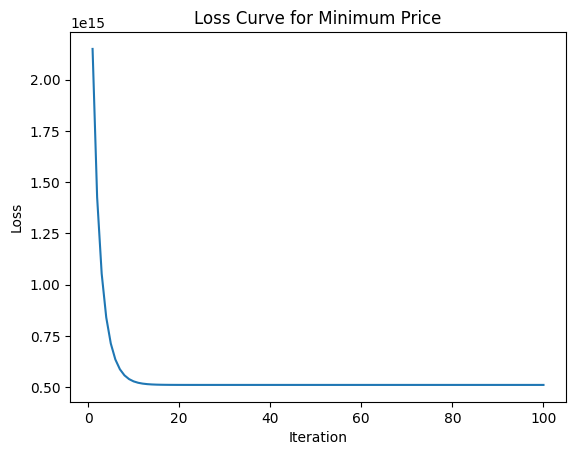

In [ ]:
# Plotting loss curve for regular min price model
plt.plot(range(1, 101), loss_min)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Loss Curve for Minimum Price")

plt.show()

Regular Maximum Price Loss Curve

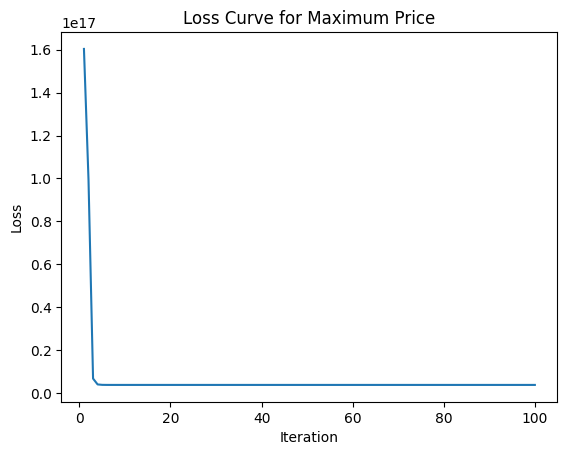

In [ ]:
# Plotting loss curve for regular max price model
plt.plot(range(1, 101), loss_max)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Loss Curve for Maximum Price")

plt.show()

Scaled + Dynamic Minimun Price Loss Curve

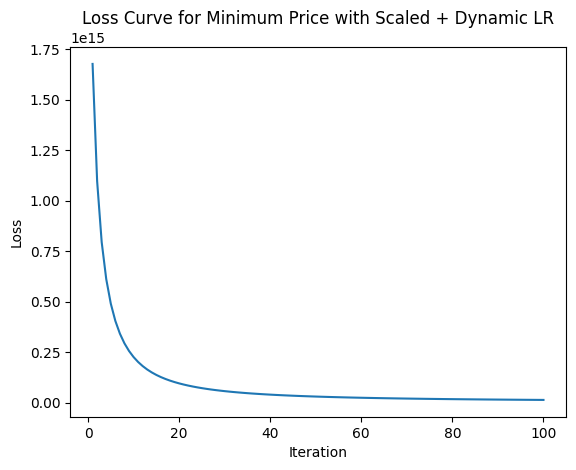

In [ ]:
# Plotting loss curve for scaled + dynamic min price model
plt.plot(range(1, 101), loss_min_sd)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Loss Curve for Minimum Price with Scaled + Dynamic LR")

plt.show()

Scaled + Dynamic Maximun Price Loss Curve

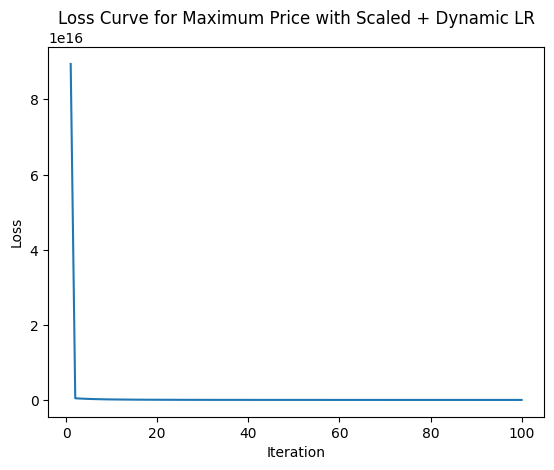

In [ ]:
# Plotting loss curve for scaled + dynamic max price model
plt.plot(range(1, 101), loss_max_sd)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Loss Curve for Maximum Price with Scaled + Dynamic LR")

plt.show()

**Prediction Calculation**

Regular Predictions

In [ ]:
# Predicting minimum prices for the missing years
predicted_min = prediction_function(
    missing_years,
    theta_0_min,
    theta_1_min
)

# Predicting maximum prices for the missing years
predicted_max = prediction_function(
    missing_years,
    theta_0_max,
    theta_1_max
)

Predictions Using Scaled + Dynamic

In [ ]:
# Scale the missing years using the same mean and standard deviation
# that were calculated from the training data
missing_years_sd_min = (missing_years - x_mean_min_sd) / x_std_min_sd

# Predict minimum prices using the scaled + dynamic model
predicted_min_sd = prediction_function(
    missing_years_sd_min,
    theta_0_min_sd,
    theta_1_min_sd
)

missing_years_sd_max = (missing_years - x_mean_max_sd) / x_std_max_sd

# Predict maximum prices using the scaled + dynamic model
predicted_max_sd = prediction_function(
    missing_years_sd_max,
    theta_0_max_sd,
    theta_1_max_sd
)

**Prediction Plots**

Regular Minimum

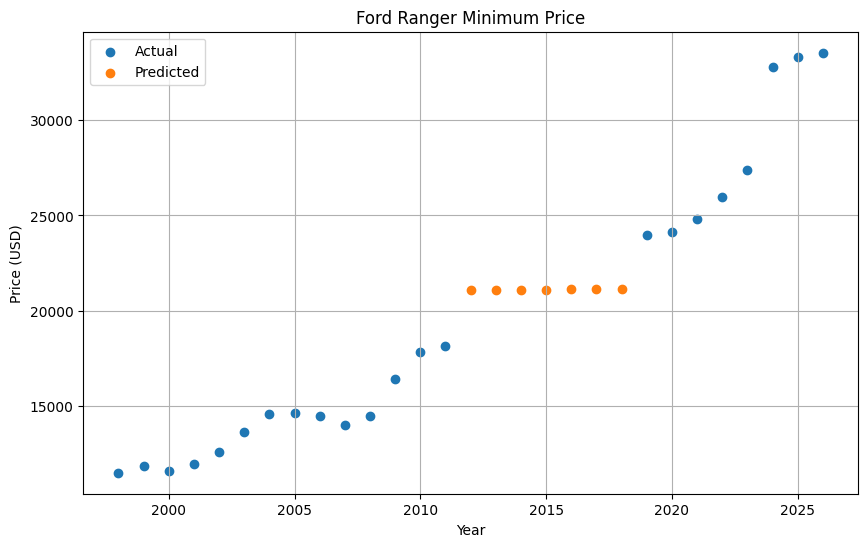

In [ ]:
# Plotting actual and predicted minimum prices

plt.figure(figsize=(10, 6))

plt.scatter(years, min_prices, color="C0", label="Actual")
plt.scatter(missing_years, predicted_min, color="C1", label="Predicted")

plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.title("Ford Ranger Minimum Price")
plt.legend()
plt.grid(True)
plt.show()

Regular Maximum

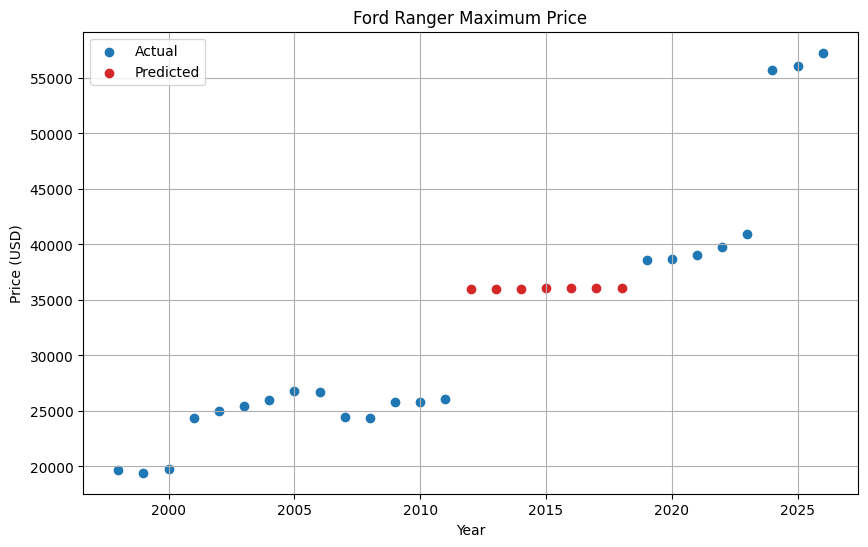

In [ ]:
# Plotting actual and predicted maximum Ranger prices

plt.figure(figsize=(10, 6))

plt.scatter(years, max_prices, color="C0", label="Actual")
plt.scatter(missing_years, predicted_max, color="C3", label="Predicted")

plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.title("Ford Ranger Maximum Price")
plt.legend()
plt.grid(True)
plt.show()

Scaled + Dynamic Minimum

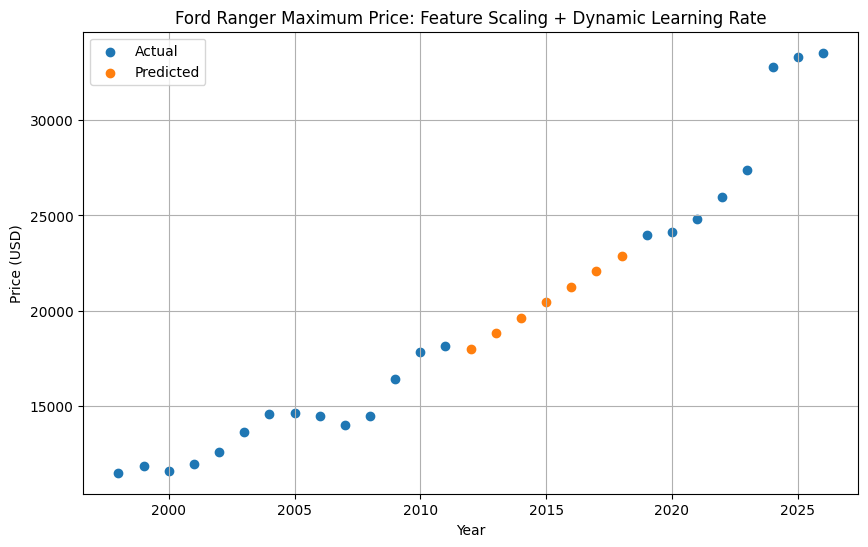

In [ ]:
# Plotting actual and predicted scaled + dynamic minimum prices
plt.figure(figsize=(10, 6))

plt.scatter(years, min_prices, color="C0", label="Actual")
plt.scatter(missing_years, predicted_min_sd, color="C1", label="Predicted")

plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.title("Ford Ranger Maximum Price: Feature Scaling + Dynamic Learning Rate")
plt.legend()
plt.grid(True)
plt.show()

Scaled + Dynamic Maximum

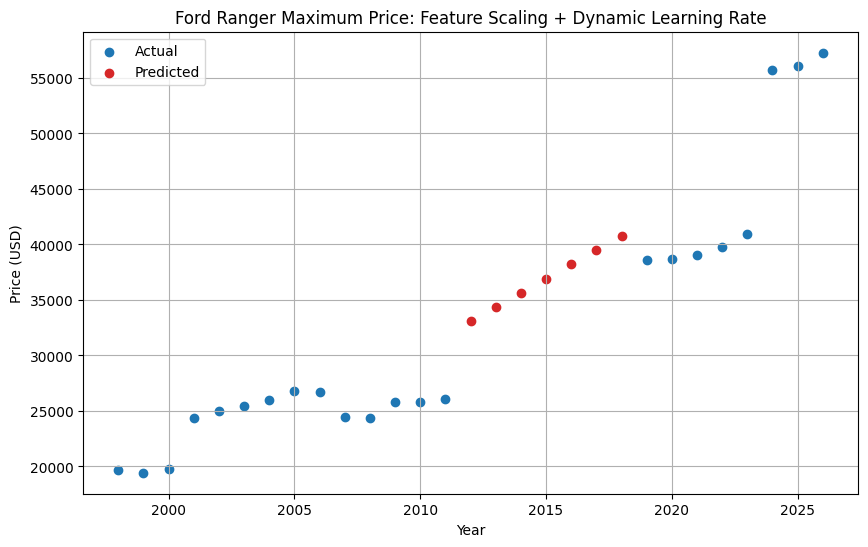

In [ ]:
# Plotting actual and predicted scaled + dynamic maximum prices

plt.figure(figsize=(10, 6))

plt.scatter(years, max_prices, color="C0", label="Actual")
plt.scatter(missing_years, predicted_max_sd, color="C3", label="Predicted")

plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.title("Ford Ranger Maximum Price: Feature Scaling + Dynamic Learning Rate")
plt.legend()
plt.grid(True)
plt.show()